# Projet DVF : étape 3, données externes et gain de chaque groupe de variables

**Entrées**
- `data/dvf_clean.parquet` (étape 1)
- `data/externe/communes_ain.csv` : coordonnées, distances, population (point 1)
- `data/externe/` : dossier de l'indice Notaires-Insee (`valeurs_trimestrielles`, `caractéristiques`), le fichier Filosofi (`DS_FILOSOFI_CC_data`), et le taux de crédit (optionnel)

**Groupes de variables comparés** : `coordonnées`, `temps` (indice des prix, taux de crédit), `profil commune` (population, revenus).

**Règle anti-fuite** : une vente n'utilise que des valeurs **publiées avant sa date**. L'indice Notaires-Insee sort environ 2 mois après la fin du trimestre : on utilise le trimestre `T-2` (`IPLA_LAG_Q = 2`). Le taux de la Banque de France sort 5 à 6 semaines après le mois : on utilise le mois `M-2` (`TAUX_LAG_M = 2`). Filosofi 2021 et la population sont antérieurs à toutes les ventes testées.

Chaque bloc externe est **optionnel** : s'il ne se charge pas, le notebook l'indique et continue sans lui.

In [15]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, os, re, glob, unicodedata
from sklearn.linear_model import Ridge
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import lightgbm as lgb
from catboost import CatBoostRegressor
warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)

SEED = 42; SEEDS = (0, 1, 2)
DATA, EXT = 'data', 'data/externe'
IPLA_LAG_Q = 2        # trimestres de décalage (2 = strictement connu à la date de vente)
TAUX_LAG_M = 2        # mois de décalage
IPLA_VARIANT = 'cvs'  # 'cvs' (corrigé des variations saisonnières) ou 'brut'
FINAL_SET = 'TOUT − temps'    # jeu de variables du modèle final (ne choisis pas sur le test !)

## 1. Fonctions de chargement des fichiers externes

In [16]:
def norm(s):
    return unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower()

def lire_tab(path, header=0):
    if path.lower().endswith(('.xlsx', '.xls')):
        return pd.read_excel(path, dtype=str, header=header)
    for enc in ('utf-8-sig', 'latin-1'):
        for sep in (';', ',', '\t', '|'):
            try:
                d = pd.read_csv(path, sep=sep, dtype=str, encoding=enc, header=header)
                if d.shape[1] > 2:
                    return d
            except Exception:
                continue
    raise ValueError(f'Lecture impossible : {path}')

def fichiers_externes():
    return [f for f in glob.glob(f'{EXT}/**/*', recursive=True)
            if os.path.isfile(f) and f.lower().endswith(('.csv', '.xlsx', '.xls', '.txt'))]

# ---------------------------------------------------------------- Filosofi (profil commune)
def charger_filosofi():
    datas = [f for f in fichiers_externes() if 'filosofi' in norm(os.path.basename(f))
             and 'meta' not in norm(os.path.basename(f))]
    if not datas: raise FileNotFoundError('aucun fichier Filosofi (data) dans data/externe')
    d = lire_tab(datas[0])
    cols = {c.upper().strip(): c for c in d.columns}
    geo = next((cols[k] for k in ('GEO', 'CODGEO', 'CODE_GEO', 'CODE') if k in cols), d.columns[0])
    d = d[d[geo].astype(str).str.match(r'^01\d{3}$')].copy()
    PREF = ['MED_SL', 'PR_MD60', 'D1_SL', 'D9_SL', 'IQ_SL']
    if 'OBS_VALUE' in cols:
        mes = next(cols[k] for k in cols if 'MEASURE' in k and 'UNIT' not in k)
        val, tcol = cols['OBS_VALUE'], cols.get('TIME_PERIOD')
        autres = [c for c in d.columns if c not in (geo, mes, val, tcol)
                  and not c.upper().startswith(('OBS_', 'CONF', 'GEO_OBJ', 'UNIT'))]
        for c in autres:
            vals = d[c].dropna().unique()
            if len(vals) > 1:
                for tot in ('_T', 'T', 'ALL', '_Z'):
                    if tot in vals:
                        d = d[d[c] == tot]; break
                else:
                    print(f'  ⚠ dimension « {c} » avec plusieurs valeurs : {list(vals)[:6]}')
        d[val] = pd.to_numeric(d[val].str.replace(',', '.'), errors='coerce')
        if tcol: d = d.sort_values(tcol)
        d = d.drop_duplicates([geo, mes], keep='last')
        wide = d.pivot_table(index=geo, columns=mes, values=val, aggfunc='first')
    else:
        wide = d.set_index(geo).apply(lambda s: pd.to_numeric(s.str.replace(',', '.'), errors='coerce'))
        wide = wide.dropna(axis=1, how='all')
    print('  indicateurs Filosofi disponibles :', list(wide.columns)[:40])
    sel = [c for c in wide.columns if str(c).upper() in PREF]
    if not sel:
        sel = [c for c in wide.columns if re.match(r'^(MED|TP60|PR_MD60|D1|D9)', str(c).upper())]
    if not sel: raise ValueError('aucun indicateur reconnu (médiane, pauvreté, déciles)')
    wide = wide[sel].copy(); wide.columns = ['fil_' + str(c).lower() for c in sel]
    wide.index.name = 'insee'
    return wide.reset_index()

# ---------------------------------------------------------------- indice Notaires-Insee
PER = re.compile(r'^(\d{4})\s*-?\s*[TQ]([1-4])$')
def charger_ipla():
    fs = fichiers_externes()
    vf = [f for f in fs if 'valeurs' in norm(os.path.basename(f)) and 'trim' in norm(os.path.basename(f))] \
         or [f for f in fs if 'valeurs' in norm(os.path.basename(f))]
    cf = [f for f in fs if 'caract' in norm(os.path.basename(f))]
    if not vf: raise FileNotFoundError('fichier valeurs_trimestrielles introuvable')
    raw = lire_tab(vf[0], header=None)
    first = raw.iloc[:, 0].astype(str).str.strip()
    if first.str.match(PER).sum() < 4:                      # séries en lignes, périodes en colonnes
        raw = raw.T.reset_index(drop=True); first = raw.iloc[:, 0].astype(str).str.strip()
    is_per = first.str.match(PER)
    r0 = int(np.argmax(is_per.values))
    head, body = raw.iloc[:r0], raw.iloc[r0:][is_per.values[r0:]].copy()
    per = first.iloc[r0:][is_per.values[r0:]].map(
        lambda s: (lambda m: f'{m.group(1)}Q{m.group(2)}')(PER.match(s)))
    lab_row = next((i for i in range(len(head)) if 'libell' in norm(head.iloc[i, 0])), None)
    id_row = next((i for i in range(len(head)) if 'idbank' in norm(head.iloc[i, 0])), None)
    ncol = raw.shape[1]
    ids = {j: (str(head.iloc[id_row, j]) if id_row is not None else
               (str(head.iloc[-1, j]) if len(head) else str(j))) for j in range(1, ncol)}
    labels = {j: (str(head.iloc[lab_row, j]) if lab_row is not None else '') for j in range(1, ncol)}
    if cf and all(not l or l == 'nan' for l in labels.values()):
        car = lire_tab(cf[0], header=0)
        ccol = next(c for c in car.columns if 'idbank' in norm(c))
        lcol = next(c for c in car.columns if 'libell' in norm(c))
        dico = dict(zip(car[ccol].astype(str).str.strip(), car[lcol]))
        labels = {j: dico.get(ids[j].strip(), '') for j in labels}
    cand = []
    for j, l in labels.items():
        n = norm(l)
        if 'ancien' not in n or any(k in n for k in ('variation', 'evolution', 'glissement', 'nombre', 'transaction')):
            continue
        reg = 0 if 'auvergne' in n else (1 if 'metropol' in n else None)
        if reg is None: continue
        typ = 'Appartement' if 'appartement' in n else ('Maison' if 'maison' in n else 'Ensemble')
        var = 'cvs' if ('cvs' in n or 'corrig' in n) else ('brut' if 'brut' in n else 'autre')
        cand.append(dict(col=j, label=l, region=reg, type=typ, variante=var))
    if not cand:
        ex = [l for l in labels.values() if 'ancien' in norm(l)][:5]
        raise ValueError(f'aucune série Auvergne-Rhône-Alpes / France métropolitaine trouvée. Exemples : {ex}')
    cdf = pd.DataFrame(cand); cdf = cdf[cdf.region == cdf.region.min()]
    out, choisies = {}, []
    ordre = [IPLA_VARIANT] + [v for v in ('cvs', 'brut', 'autre') if v != IPLA_VARIANT]
    for typ in ('Ensemble', 'Appartement', 'Maison'):
        sub = cdf[cdf.type == typ]
        for v in ordre:
            r = sub[sub.variante == v]
            if len(r):
                r = r.iloc[0]; choisies.append((typ, r.label))
                out['ipla_' + typ] = pd.to_numeric(body[int(r.col)].astype(str).str.replace(',', '.'),
                                                   errors='coerce').values
                break
    print('  séries retenues :'); [print('   -', t, '|', l[:110]) for t, l in choisies]
    tab = pd.DataFrame(out, index=pd.PeriodIndex(per.values, freq='Q')).sort_index()
    tab = tab[~tab.index.duplicated(keep='last')]
    return tab.reindex(pd.period_range(tab.index.min(), tab.index.max(), freq='Q'))

def joindre_ipla(d, ipla, lag):
    q = d['date'].dt.to_period('Q') - lag
    idx = pd.Series(np.nan, index=d.index); yoy = pd.Series(np.nan, index=d.index)
    for typ in ('Appartement', 'Maison'):
        col = f'ipla_{typ}' if f'ipla_{typ}' in ipla else 'ipla_Ensemble'
        s = ipla[col]; sy = s / s.shift(4) - 1
        m = d['type_local'] == typ
        idx[m] = q[m].map(s).values; yoy[m] = q[m].map(sy).values
    return idx, yoy

# ---------------------------------------------------------------- taux de crédit (Banque de France)
DATE_RE = r'^\s*(\d{4}-\d{2}(-\d{2})?|\d{2}/\d{4}|\d{2}/\d{2}/\d{4}|\d{4}M\d{2})\s*$'
def charger_taux():
    fs = [f for f in fichiers_externes() if not any(k in norm(f) for k in ('ipla', 'filosofi', 'communes', 'valeurs', 'caract'))
          and any(k in norm(os.path.basename(f)) for k in ('taux', 'mir', 'credit'))]
    if not fs: raise FileNotFoundError('aucun fichier de taux de crédit dans data/externe')
    raw = lire_tab(fs[0], header=None)
    best = max(range(raw.shape[1]), key=lambda c: raw[c].astype(str).str.match(DATE_RE).sum())
    mask = raw[best].astype(str).str.match(DATE_RE)
    if mask.sum() < 24: raise ValueError('colonne de dates mensuelles non trouvée')
    def parse(s):
        s = s.strip()
        if re.match(r'^\d{4}M\d{2}$', s): return pd.Period(s[:4] + '-' + s[5:], 'M')
        if re.match(r'^\d{2}/\d{4}$', s): return pd.Period(s[3:] + '-' + s[:2], 'M')
        if re.match(r'^\d{2}/\d{2}/\d{4}$', s): return pd.Period(pd.to_datetime(s, dayfirst=True), 'M')
        return pd.Period(s[:7], 'M')
    per = pd.PeriodIndex([parse(s) for s in raw.loc[mask, best].astype(str)], freq='M')
    bc, bn = None, -1
    for c in range(raw.shape[1]):
        if c == best: continue
        v = pd.to_numeric(raw.loc[mask, c].astype(str).str.replace(',', '.'), errors='coerce')
        n = v.between(0.2, 15).sum()
        if n > bn: bc, bn = c, n
    v = pd.to_numeric(raw.loc[mask, bc].astype(str).str.replace(',', '.'), errors='coerce')
    s = pd.Series(v.values, index=per).groupby(level=0).mean().sort_index()
    print(f'  fichier : {os.path.basename(fs[0])} | colonne de taux : {bc} | {s.index.min()} → {s.index.max()}')
    return s.reindex(pd.period_range(s.index.min(), s.index.max(), freq='M'))

## 2. Chargement de la base et jointures

In [17]:
df = pd.read_parquet(f'{DATA}/dvf_clean.parquet')
com = pd.read_csv(f'{EXT}/communes_ain.csv', dtype={'insee': str})
df = df.merge(com.drop(columns=['nom_geo']), on='insee', how='left')
df['log_population'] = np.log1p(df['population'])
print('ventes sans coordonnées :', df['lat'].isna().sum())

GEO = ['lat', 'lon', 'dist_geneve_km', 'dist_lyon_km', 'dist_bourg_km']
PROFIL = ['population', 'log_population']
TEMPS = []
IPLA = TAUX = None

print('\n[Filosofi]')
try:
    fil = charger_filosofi()
    df = df.merge(fil, on='insee', how='left')
    fcols = [c for c in fil.columns if c != 'insee']
    df['fil_manquant'] = df[fcols[0]].isna().astype(int)
    print(f'  communes avec indicateurs : {fil.shape[0]} | ventes sans indicateurs : {df.fil_manquant.mean():.1%}')
    for c in fcols: df[c] = df[c].fillna(fil[c].median())        # imputation par la médiane du département
    PROFIL += fcols + ['fil_manquant']
except Exception as e:
    print('  ⚠ Filosofi non utilisé :', repr(e))

print('\n[Indice Notaires-Insee]')
try:
    IPLA = charger_ipla()
    df['ipla_lag'], df['ipla_yoy_lag'] = joindre_ipla(df, IPLA, IPLA_LAG_Q)
    df['log_ipla_lag'] = np.log(df['ipla_lag'])
    print(f'  couverture {IPLA.index.min()} → {IPLA.index.max()} | valeurs manquantes sur les ventes : {df.ipla_lag.isna().mean():.1%}')
    TEMPS += ['ipla_lag', 'ipla_yoy_lag']
except Exception as e:
    print('  ⚠ indice non utilisé :', repr(e))

print('\n[Taux de crédit]')
try:
    TAUX = charger_taux()
    m = df['date'].dt.to_period('M') - TAUX_LAG_M
    df['taux_lag'] = m.map(TAUX).values
    df['taux_chg12'] = (m.map(TAUX) - (m - 12).map(TAUX)).values
    print(f'  valeurs manquantes sur les ventes : {df.taux_lag.isna().mean():.1%}')
    TEMPS += ['taux_lag', 'taux_chg12']
except Exception as e:
    print('  ⚠ taux non utilisé :', repr(e))

print('\nGroupes :', {'coordonnées': GEO, 'temps': TEMPS, 'profil commune': PROFIL})

ventes sans coordonnées : 16

[Filosofi]
  indicateurs Filosofi disponibles : ['D1_SL', 'D9_SL', 'IR_D9_D1_SL', 'MED_SL', 'NUM_CU', 'NUM_HH', 'NUM_PER', 'PR_MD60', 'S_DIR_TAX_DI', 'S_EI_DI', 'S_EI_DI_N_SAL', 'S_EI_DI_SAL', 'S_EI_DI_UNE', 'S_HH_TAX', 'S_INC_ASS_DI', 'S_RET_PEN_DI', 'S_SOC_BEN_DI', 'S_SOC_BEN_DI_FAM_BEN', 'S_SOC_BEN_DI_HOU_BEN', 'S_SOC_BEN_DI_MIN_SOC']
  communes avec indicateurs : 387 | ventes sans indicateurs : 31.5%

[Indice Notaires-Insee]
  séries retenues :
   - Ensemble | Indice des prix des logements anciens - Auvergne-Rhône-Alpes - Ensemble - Base 100 en moyenne annuelle 2015 - 
   - Appartement | Indice des prix des logements anciens - Auvergne-Rhône-Alpes - Appartements - Base 100 en moyenne annuelle 201
   - Maison | Indice des prix des logements anciens - Auvergne-Rhône-Alpes - Maisons - Base 100 en moyenne annuelle 2015 - S
  couverture 1992Q1 → 2026Q2 | valeurs manquantes sur les ventes : 0.0%

[Taux de crédit]
  ⚠ taux non utilisé : FileNotFoundError('auc

### Audit anti-fuite : quelle valeur externe chaque vente utilise-t-elle ?

In [18]:
aud = df[['date', 'type_local']].sample(6, random_state=1).copy()
aud['trimestre_vente'] = aud['date'].dt.to_period('Q').astype(str)
aud['trimestre_indice_utilisé'] = (aud['date'].dt.to_period('Q') - IPLA_LAG_Q).astype(str)
aud['mois_vente'] = aud['date'].dt.to_period('M').astype(str)
aud['mois_taux_utilisé'] = (aud['date'].dt.to_period('M') - TAUX_LAG_M).astype(str)
display(aud.sort_values('date'))
assert (df['date'].dt.to_period('Q') - IPLA_LAG_Q < df['date'].dt.to_period('Q')).all()

,date,type_local,trimestre_vente,trimestre_indice_utilisé,mois_vente,mois_taux_utilisé
13453,2022-07-06,Maison,2022Q3,2022Q1,2022-07,2022-05
16213,2022-12-07,Maison,2022Q4,2022Q2,2022-12,2022-10
5235,2023-10-10,Appartement,2023Q4,2023Q2,2023-10,2023-08
5529,2023-11-16,Appartement,2023Q4,2023Q2,2023-11,2023-09
22610,2024-06-13,Maison,2024Q2,2023Q4,2024-06,2024-04
27383,2025-07-11,Maison,2025Q3,2025Q1,2025-07,2025-05


## 3. Variables, split temporel, métriques

In [19]:
df['y'] = np.log(df['prix_m2'])
df['carrez_dispo'] = df['surface_carrez'].notna().astype(int)
df['log_terrain'] = np.log1p(df['surface_terrain'])
df['mois_sin'] = np.sin(2*np.pi*df['mois']/12); df['mois_cos'] = np.cos(2*np.pi*df['mois']/12)
CP_GEX = {'01170','01210','01220','01280','01630','01710'}
df['pays_de_gex'] = df['code_postal'].isin(CP_GEX).astype(int)

BASE_NUM = ['surface_bati','log_surface','pieces','surface_terrain','log_terrain','nb_dependances',
            'a_dependance','surface_carrez','carrez_dispo','mois','mois_sin','mois_cos']
CAT = ['type_local', 'commune']

train = df[df.annee <= 2023]; val = df[df.annee == 2024]
trainval = df[df.annee <= 2024]; test = df[df.annee == 2025]
print({n: len(d) for n, d in [('train', train), ('val', val), ('trainval', trainval), ('test', test)]})
T = test['prix_m2'].values

def metrics(y_true, y_pred):
    e = y_pred - y_true; ape = np.abs(e) / y_true
    return {'MAE': np.abs(e).mean(), 'MAPE %': ape.mean()*100, 'MedAPE %': np.median(ape)*100,
            '±10 %': (ape <= .10).mean()*100, '±20 %': (ape <= .20).mean()*100,
            'biais médian %': np.median(e / y_true)*100,
            'R2 (log)': 1 - ((np.log(y_pred)-np.log(y_true))**2).sum() / ((np.log(y_true)-np.log(y_true).mean())**2).sum()}

cats = {c: trainval[c].astype('category').cat.categories for c in CAT}
def prep_lgb(d, feats):
    X = d[BASE_NUM + feats + CAT].copy()
    for c in CAT: X[c] = pd.Categorical(X[c], categories=cats[c])
    return X

LGB_PARAMS = dict(objective='regression', learning_rate=0.03, num_leaves=31, min_child_samples=20,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                  cat_smooth=20, cat_l2=10, min_data_per_group=10, verbose=-1)

{'train': 16062, 'val': 6415, 'trainval': 22477, 'test': 7648}


## 4. Fonctions d'entraînement
`y_off` permet la **déflation de la cible** : on apprend `log(prix) − log(indice)` puis on réinjecte l'indice (connu, car décalé) à la prédiction.

In [20]:
def run_lgb(feats, y_off=None, data=None):
    tr, va, tv, te = data if data is not None else (train, val, trainval, test)
    off = (lambda d: 0) if y_off is None else (lambda d: d[y_off].values)
    es = lgb.LGBMRegressor(n_estimators=5000, random_state=SEED, **LGB_PARAMS)
    es.fit(prep_lgb(tr, feats), tr['y'].values - off(tr),
           eval_set=[(prep_lgb(va, feats), va['y'].values - off(va))],
           callbacks=[lgb.early_stopping(100, verbose=False)])
    best = max(int(es.best_iteration_), 30)
    models = [lgb.LGBMRegressor(n_estimators=best, random_state=s, **LGB_PARAMS)
              .fit(prep_lgb(tv, feats), tv['y'].values - off(tv)) for s in SEEDS]
    lp = np.mean([m.predict(prep_lgb(te, feats)) for m in models], axis=0)
    return dict(pred=np.exp(lp + off(te)), best=best, models=models, es=es, feats=feats, y_off=y_off)

def run_ridge(feats):
    num = BASE_NUM + feats
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=3), CAT)])
    best = None
    for a in [0.3, 1, 3, 10, 30, 100]:
        p = Pipeline([('p', prep), ('m', Ridge(alpha=a))]).fit(train[num + CAT], train['y'])
        r = np.sqrt(((p.predict(val[num + CAT]) - val['y'])**2).mean())
        if best is None or r < best[0]: best = (r, a)
    p = Pipeline([('p', prep), ('m', Ridge(alpha=best[1]))]).fit(trainval[num + CAT], trainval['y'])
    return np.exp(p.predict(test[num + CAT]))

def delta_ci(p_ref, p_new, n=500):
    a = np.abs(p_ref - T) / T; b = np.abs(p_new - T) / T
    rng = np.random.default_rng(SEED); d = []
    for _ in range(n):
        i = rng.integers(0, len(T), len(T))
        d.append([np.median(b[i]) - np.median(a[i]), b[i].mean() - a[i].mean()])
    return np.percentile(np.array(d) * 100, [2.5, 97.5], axis=0)     # [[bas medAPE, bas MAPE],[haut, haut]]

## 5. Tableau d'ablation : gain de chaque groupe
- **Ajout** : base de l'étape 2 + un seul groupe.
- **Retrait** : toutes les variables moins un groupe.
- Écarts en points de pourcentage (négatif = amélioration), avec intervalle de confiance bootstrap **apparié** à 95 % sur LightGBM (✓ = l'intervalle exclut 0).

In [21]:
ALL = GEO + TEMPS + PROFIL
SETS = {'0 · base (étape 2)': []}
SETS['+ coordonnées'] = GEO
if TEMPS: SETS['+ temps'] = TEMPS
SETS['+ profil commune'] = PROFIL
SETS['TOUT'] = ALL
SETS['TOUT − coordonnées'] = [f for f in ALL if f not in GEO]
if TEMPS: SETS['TOUT − temps'] = [f for f in ALL if f not in TEMPS]
SETS['TOUT − profil commune'] = [f for f in ALL if f not in PROFIL]

R = {}
for name, feats in SETS.items():
    r = run_lgb(feats); r['ridge'] = run_ridge(feats); R[name] = r
    print(f'{name:28s} arbres={r["best"]:4d}  MedAPE={metrics(T, r["pred"])["MedAPE %"]:.2f}')

# variantes « temps par déflation »
if 'log_ipla_lag' in df:
    R['+ temps (déflation de la cible)'] = run_lgb([], y_off='log_ipla_lag')
    R['TOUT − temps + déflation'] = run_lgb([f for f in ALL if f not in TEMPS], y_off='log_ipla_lag')
    for k in ('+ temps (déflation de la cible)', 'TOUT − temps + déflation'):
        R[k]['ridge'] = np.nan * np.ones(len(T))

ref = R['0 · base (étape 2)']['pred']
rows = []
for name, r in R.items():
    m = metrics(T, r['pred']); mr = metrics(T, r['ridge']) if not np.isnan(r['ridge']).all() else {}
    lo, hi = delta_ci(ref, r['pred']) if name != '0 · base (étape 2)' else (np.zeros(2), np.zeros(2))
    rows.append({'jeu de variables': name, 'MedAPE %': m['MedAPE %'], 'Δ MedAPE': m['MedAPE %'] - metrics(T, ref)['MedAPE %'],
                 'IC95 Δ MedAPE': f'[{lo[0]:+.2f} ; {hi[0]:+.2f}]', 'sig.': '✓' if (lo[0] > 0 or hi[0] < 0) else '',
                 'MAPE %': m['MAPE %'], 'Δ MAPE': m['MAPE %'] - metrics(T, ref)['MAPE %'],
                 '±20 %': m['±20 %'], 'biais médian %': m['biais médian %'],
                 'Ridge MedAPE %': mr.get('MedAPE %', np.nan)})
ABL = pd.DataFrame(rows).set_index('jeu de variables')
display(ABL.round(2))

0 · base (étape 2)           arbres= 431  MedAPE=16.33
+ coordonnées                arbres= 263  MedAPE=16.22
+ temps                      arbres= 642  MedAPE=16.83
+ profil commune             arbres= 380  MedAPE=16.08
TOUT                         arbres= 471  MedAPE=16.62
TOUT − coordonnées           arbres= 503  MedAPE=16.69
TOUT − temps                 arbres= 345  MedAPE=16.08
TOUT − profil commune        arbres= 354  MedAPE=16.79


,MedAPE %,Δ MedAPE,IC95 Δ MedAPE,sig.,MAPE %,Δ MAPE,±20 %,biais médian %,Ridge MedAPE %
jeu de variables,,,,,,,,,
0 · base (étape 2),16.33,0.00,[+0.00 ; +0.00],,24.24,0.00,59.87,-4.01,17.48
+ coordonnées,16.22,-0.11,[-0.34 ; +0.08],,24.02,-0.22,59.83,-4.24,17.52
+ temps,16.83,0.50,[+0.30 ; +0.77],✓,23.90,-0.34,58.45,-6.46,18.03
+ profil commune,16.08,-0.25,[-0.45 ; -0.00],✓,24.10,-0.14,59.90,-4.14,17.28
TOUT,16.62,0.29,[+0.05 ; +0.58],✓,23.68,-0.56,58.70,-6.63,18.03
TOUT − coordonnées,16.69,0.36,[+0.14 ; +0.58],✓,23.79,-0.45,58.67,-6.57,17.95
TOUT − temps,16.08,-0.25,[-0.46 ; -0.04],✓,24.00,-0.25,59.88,-4.25,17.42
TOUT − profil commune,16.79,0.46,[+0.19 ; +0.78],✓,23.73,-0.52,58.93,-6.41,18.00
+ temps (déflation de la cible),17.07,0.74,[+0.53 ; +0.93],✓,24.09,-0.16,57.96,-6.36,NaN


### Graphique du gain par groupe (LightGBM, ajout à la base)

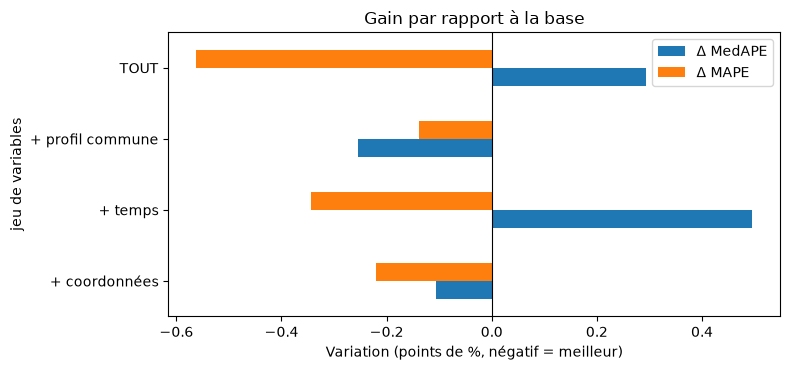

In [22]:
g = ABL.loc[[k for k in ['+ coordonnées', '+ temps', '+ profil commune', 'TOUT'] if k in ABL.index], ['Δ MedAPE', 'Δ MAPE']]
g.plot.barh(figsize=(8, 3.8)); plt.axvline(0, color='k', lw=.8)
plt.xlabel('Variation (points de %, négatif = meilleur)'); plt.title('Gain par rapport à la base'); plt.tight_layout(); plt.show()

### Sensibilité au décalage de l'indice (fuite)
Un décalage de 0 ou 1 trimestre utilise une valeur **pas encore publiée** à la date de vente : le gain correspondant est optimiste et ne serait pas reproductible en conditions réelles.

In [23]:
if IPLA is not None:
    rows = []
    for lag in (0, 1, 2, 3, 4):
        a, b = joindre_ipla(df, IPLA, lag)
        tmp = df.assign(ipla_lag=a, ipla_yoy_lag=b)
        r = run_lgb(['ipla_lag', 'ipla_yoy_lag'], data=(tmp[tmp.annee <= 2023], tmp[tmp.annee == 2024],
                                                         tmp[tmp.annee <= 2024], tmp[tmp.annee == 2025]))
        m = metrics(T, r['pred'])
        rows.append({'décalage (trimestres)': lag, 'valide sans fuite': 'oui' if lag >= 2 else 'NON (info seulement)',
                     'MedAPE %': m['MedAPE %'], 'MAPE %': m['MAPE %'], 'biais médian %': m['biais médian %']})
    display(pd.DataFrame(rows).set_index('décalage (trimestres)').round(2))

,valide sans fuite,MedAPE %,MAPE %,biais médian %
décalage (trimestres),,,,
0,NON (info seulement),16.74,24.02,-5.71
1,NON (info seulement),16.79,23.97,-5.96
2,oui,16.83,23.90,-6.46
3,oui,16.76,23.94,-6.43
4,oui,16.70,23.97,-5.92


## 6. Modèles finaux avec toutes les variables, comparés à l'étape 2

In [24]:
FEATS_F = SETS[FINAL_SET]
rf = R[FINAL_SET]
PRED = {}
# baseline B1 : médiane commune x type lissée
g_type = trainval.groupby('type_local')['prix_m2'].median()
st = trainval.groupby(['commune', 'type_local'])['prix_m2'].agg(['median', 'count']).reset_index()
mm = test[['commune', 'type_local']].merge(st, on=['commune', 'type_local'], how='left')
w = mm['count'].fillna(0).values / (mm['count'].fillna(0).values + 5)
PRED['B1 médiane commune×type'] = w * mm['median'].fillna(0).values + (1 - w) * test['type_local'].map(g_type).values
PRED['Ridge'] = rf['ridge']
PRED['LightGBM'] = rf['pred']

def prep_cb(d, feats):
    X = d[BASE_NUM + feats + CAT].copy()
    for c in CAT: X[c] = X[c].astype(str)
    return X
cb_es = CatBoostRegressor(iterations=3000, learning_rate=0.05, depth=6, random_seed=SEED, verbose=0, od_type='Iter', od_wait=100)
cb_es.fit(prep_cb(train, FEATS_F), train['y'], cat_features=CAT, eval_set=(prep_cb(val, FEATS_F), val['y']))
CB_IT = max(int(cb_es.get_best_iteration()), 50)
cb = CatBoostRegressor(iterations=CB_IT, learning_rate=0.05, depth=6, random_seed=SEED, verbose=0)
cb.fit(prep_cb(trainval, FEATS_F), trainval['y'], cat_features=CAT)
PRED['CatBoost'] = np.exp(cb.predict(prep_cb(test, FEATS_F)))
PRED['Moyenne LGBM + CatBoost'] = np.sqrt(PRED['LightGBM'] * PRED['CatBoost'])

RES3 = pd.DataFrame({k: metrics(T, v) for k, v in PRED.items()}).T.sort_values('MedAPE %')
display(RES3.round(2))

if os.path.exists(f'{DATA}/etape2_metriques.csv'):
    old = pd.read_csv(f'{DATA}/etape2_metriques.csv', index_col=0)
    cols = ['MedAPE %', 'MAPE %', '±20 %', 'MAE']
    comp = old[cols].join(RES3[cols], lsuffix=' étape 2', rsuffix=' étape 3', how='inner')
    for c in cols: comp[c + ' Δ'] = comp[c + ' étape 3'] - comp[c + ' étape 2']
    print('Étape 3 contre étape 2 (mêmes modèles) :'); display(comp.round(2))
BEST = RES3.index[0]; print('Meilleur modèle :', BEST)

,MAE,MAPE %,MedAPE %,±10 %,±20 %,biais médian %,R2 (log)
LightGBM,564.23,24.00,16.08,31.41,59.88,-4.25,0.61
Moyenne LGBM + CatBoost,561.71,23.91,16.17,31.93,60.21,-4.11,0.61
CatBoost,563.77,24.03,16.31,32.01,59.88,-4.30,0.61
Ridge,595.59,25.36,17.42,29.16,56.15,-4.86,0.58
B1 médiane commune×type,628.37,28.80,17.89,29.39,55.36,0.06,0.50


Étape 3 contre étape 2 (mêmes modèles) :


,MedAPE % étape 2,MAPE % étape 2,±20 % étape 2,MAE étape 2,MedAPE % étape 3,MAPE % étape 3,±20 % étape 3,MAE étape 3,MedAPE % Δ,MAPE % Δ,±20 % Δ,MAE Δ
Moyenne LGBM + CatBoost,16.18,24.22,59.44,568.02,16.17,23.91,60.21,561.71,-0.01,-0.31,0.77,-6.31
LightGBM,16.26,24.27,59.61,569.73,16.08,24.00,59.88,564.23,-0.18,-0.27,0.27,-5.50
CatBoost,16.51,24.72,58.49,578.67,16.31,24.03,59.88,563.77,-0.20,-0.69,1.39,-14.90
B1 médiane commune×type,17.89,28.80,55.36,628.37,17.89,28.80,55.36,628.37,0.00,0.00,0.00,0.00


Meilleur modèle : LightGBM


## 7. Erreurs par segment et dérive temporelle (étape 3 contre étape 2)

In [25]:
seg = test[['date', 'commune', 'type_local', 'pays_de_gex', 'surface_bati', 'prix_m2']].copy()
seg['pred'] = PRED[BEST]
seg['ape'] = np.abs(seg.pred - seg.prix_m2) / seg.prix_m2 * 100
seg['biais'] = (seg.pred - seg.prix_m2) / seg.prix_m2 * 100
seg['tranche_prix'] = pd.cut(seg.prix_m2, [0, 1000, 1500, 2000, 3000, 4000, 12000])
seg['mois'] = seg.date.dt.month

p2 = None
if os.path.exists(f'{DATA}/etape2_predictions_test.csv'):
    o = pd.read_csv(f'{DATA}/etape2_predictions_test.csv')
    if len(o) == len(seg) and np.allclose(o['prix_m2'].values, seg['prix_m2'].values):
        p2 = o['pred_Moyenne'].values
        seg['ape_e2'] = np.abs(p2 - seg.prix_m2) / seg.prix_m2 * 100
        seg['biais_e2'] = (p2 - seg.prix_m2) / seg.prix_m2 * 100
    else:
        print('Prédictions de l\'étape 2 non alignables : comparaison par segment ignorée.')

def tab(col):
    g = seg.groupby(col, observed=True)
    t = pd.DataFrame({'n': g.size(), 'MedAPE étape 3': g['ape'].median(), 'biais étape 3': g['biais'].median()})
    if p2 is not None:
        t['MedAPE étape 2'] = g['ape_e2'].median(); t['biais étape 2'] = g['biais_e2'].median()
    return t.round(1)

for c in ['type_local', 'pays_de_gex', 'tranche_prix', 'mois']:
    print(f'--- par {c}'); display(tab(c))
print('--- communes les plus vendues'); display(tab('commune').loc[seg['commune'].value_counts().head(15).index].sort_values('MedAPE étape 3'))

--- par type_local


,n,MedAPE étape 3,biais étape 3,MedAPE étape 2,biais étape 2
type_local,,,,,
Appartement,2768,15.4,-5.7,15.3,-5.4
Maison,4880,16.5,-3.4,16.8,-3.1


--- par pays_de_gex


,n,MedAPE étape 3,biais étape 3,MedAPE étape 2,biais étape 2
pays_de_gex,,,,,
0,6306,16.8,-2.9,17.0,-2.3
1,1342,13.6,-8.6,13.5,-8.8


--- par tranche_prix


,n,MedAPE étape 3,biais étape 3,MedAPE étape 2,biais étape 2
tranche_prix,,,,,
"(0, 1000]",252,99.1,99.1,112.1,112.1
"(1000, 1500]",753,37.0,36.6,38.8,38.8
"(1500, 2000]",1199,15.3,8.1,14.9,9.1
"(2000, 3000]",2696,14.1,-6.5,13.9,-6.5
"(3000, 4000]",1321,15.4,-11.0,15.8,-11.5
"(4000, 12000]",1427,14.5,-13.6,14.6,-13.8


--- par mois


,n,MedAPE étape 3,biais étape 3,MedAPE étape 2,biais étape 2
mois,,,,,
1,487,16.7,-5.0,17.0,-5.9
2,494,16.7,-4.1,16.4,-4.3
3,637,15.5,-3.5,15.9,-3.3
4,579,17.3,-3.5,16.9,-4.2
5,478,15.4,-4.1,15.5,-3.7
6,680,17.0,-5.3,17.6,-4.3
7,883,16.0,-4.2,15.9,-3.9
8,503,13.1,-4.1,13.6,-4.0
9,721,16.2,-4.5,16.6,-3.4


--- communes les plus vendues


,n,MedAPE étape 3,biais étape 3,MedAPE étape 2,biais étape 2
commune,,,,,
LAGNIEU,100,11.0,-1.4,12.0,-2.0
PREVESSIN-MOENS,114,11.6,-4.4,11.8,-5.1
MEXIMIEUX,87,13.1,2.4,13.6,4.0
FERNEY-VOLTAIRE,188,13.5,-1.7,13.0,-3.2
MIRIBEL,115,13.6,-3.4,13.0,-3.6
ST-GENIS-POUILLY,164,13.7,-10.4,13.1,-11.1
GEX,226,13.8,-10.4,12.6,-8.7
DIVONNE-LES-BAINS,171,15.2,-9.4,15.2,-9.3
MONTLUEL,99,15.2,-3.8,14.9,-2.9


## 8. Intervalles de prédiction à 80 % : conformelle globale contre conformelle par segment (Mondrian)
La conformelle **Mondrian** calibre un écart par groupe (type de bien × Pays de Gex) au lieu d'un écart unique, ce qui corrige la sur-couverture du Pays de Gex vue à l'étape 2.

In [26]:
ALPHA = 0.20
es = rf['es']; fe = rf['feats']
rv = np.abs(val['y'].values - es.predict(prep_lgb(val, fe)))
def qconf(r):
    n = len(r); return np.quantile(r, min(1, np.ceil((n + 1) * (1 - ALPHA)) / n))
q_glob = qconf(rv)
grp_v = (val['type_local'] + '_' + val['pays_de_gex'].astype(str)).values
grp_t = (test['type_local'] + '_' + test['pays_de_gex'].astype(str)).values
q_grp = {g: (qconf(rv[grp_v == g]) if (grp_v == g).sum() >= 30 else q_glob) for g in np.unique(grp_v)}
centre = np.log(PRED['LightGBM'])
qt = np.array([q_grp.get(g, q_glob) for g in grp_t])
IV = {'globale': (np.exp(centre - q_glob), np.exp(centre + q_glob)),
      'Mondrian (type × Gex)': (np.exp(centre - qt), np.exp(centre + qt))}
rows = []
for k, (lo, hi) in IV.items():
    ok = (T >= lo) & (T <= hi)
    rows.append({'méthode': k, 'couverture %': ok.mean()*100, 'largeur relative médiane %': np.median((hi - lo) / np.exp(centre))*100,
                 'couv. Appartement': ok[test.type_local.values == 'Appartement'].mean()*100,
                 'couv. Maison': ok[test.type_local.values == 'Maison'].mean()*100,
                 'couv. Pays de Gex': ok[test.pays_de_gex.values == 1].mean()*100,
                 'couv. hors Gex': ok[test.pays_de_gex.values == 0].mean()*100})
print('Objectif :', (1 - ALPHA) * 100, '%'); display(pd.DataFrame(rows).set_index('méthode').round(1))

Objectif : 80.0 %


,couverture %,largeur relative médiane %,couv. Appartement,couv. Maison,couv. Pays de Gex,couv. hors Gex
méthode,,,,,,
globale,81.2,70.2,85.6,78.8,92.5,78.9
Mondrian (type × Gex),81.5,79.7,80.6,82.0,81.6,81.5


## 9. Importance des variables, par variable et par groupe

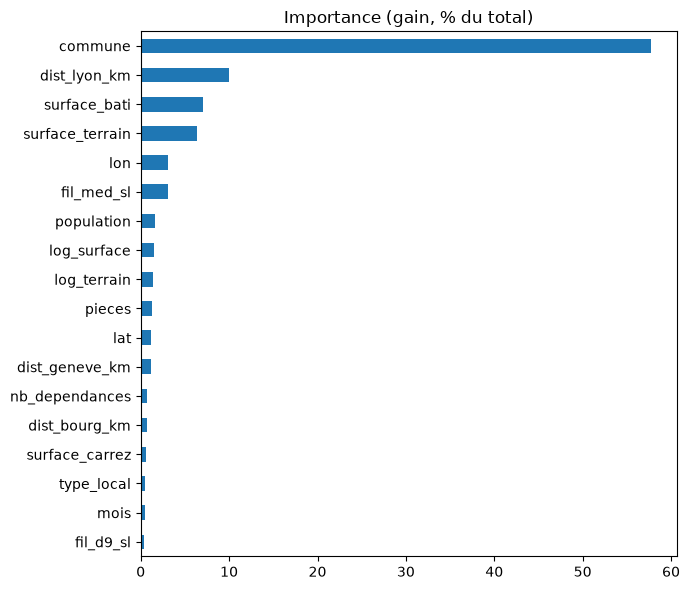

,% du gain
base (bien + commune),78.3
coordonnées,16.1
profil commune,5.7


In [27]:
mdl = rf['models'][0]
imp = pd.Series(mdl.booster_.feature_importance('gain'), index=mdl.booster_.feature_name())
imp = imp / imp.sum() * 100
imp.sort_values().tail(18).plot.barh(figsize=(7, 6), title='Importance (gain, % du total)'); plt.tight_layout(); plt.show()
grp = {**{f: 'coordonnées' for f in GEO}, **{f: 'temps' for f in TEMPS}, **{f: 'profil commune' for f in PROFIL}}
display(imp.groupby(lambda f: grp.get(f, 'base (bien + commune)')).sum().sort_values(ascending=False).round(1).to_frame('% du gain'))

## 10. Sauvegarde

In [28]:
ABL.to_csv(f'{DATA}/etape3_ablation.csv'); RES3.to_csv(f'{DATA}/etape3_metriques.csv')
out = test[['date', 'commune', 'type_local', 'surface_bati', 'prix_m2']].copy()
for k, v in PRED.items(): out['pred_' + k.split()[0]] = v
out['lo80_mondrian'], out['hi80_mondrian'] = IV['Mondrian (type × Gex)']
out.to_csv(f'{DATA}/etape3_predictions_test.csv', index=False)
df.to_parquet(f'{DATA}/dvf_features_etape3.parquet', index=False)
print('Sauvegardé : etape3_ablation.csv, etape3_metriques.csv, etape3_predictions_test.csv, dvf_features_etape3.parquet')

Sauvegardé : etape3_ablation.csv, etape3_metriques.csv, etape3_predictions_test.csv, dvf_features_etape3.parquet


## À retenir pour le rapport
1. Le tableau d'ablation : gain (ou non) de chaque groupe, avec intervalle de confiance. Un groupe dont l'intervalle contient 0 n'apporte rien de prouvé.
2. La sensibilité au décalage : la part du gain temporel qui vient d'une information non encore publiée n'est pas reproductible.
3. La comparaison déflation contre variable : laquelle corrige le mieux le biais de 2025.
4. Les limites : Filosofi 2021 est antérieur à tout, la population est une valeur récente, l'indice publié est révisable (la version téléchargée est la version révisée).